In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

sys.path.append(str(Path("..").resolve()))

import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, balanced_accuracy_score

from src import preprocessing
from src.conversions import ZERO_POINT_JY, build_feature_matrix, combine_first_column
from src.clustering import fit_umap, run_hdbscan_grid, select_best_config
from src.interpretation import (
    train_lightgbm_surrogate,
    compute_shap_values,
    per_cluster_shap_tables,
    plot_shap_global,
    plot_shap_per_cluster,
    plot_cluster_composition,
)

DATA_DIR = Path("../data/raw")
RESULTS_DIR = Path("../results")


Failed to read module file 'C:\Users\I\miniforge3\envs\quant\Lib\shlex.py' for module 'shlex': UnicodeDecodeError
Traceback (most recent call last):
  File "C:\Users\I\miniforge3\envs\quant\Lib\site-packages\IPython\core\extensions.py", line 62, in load_extension
    return self._load_extension(module_str)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\I\miniforge3\envs\quant\Lib\site-packages\IPython\core\extensions.py", line 77, in _load_extension
    mod = import_module(module_str)
          ^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\I\miniforge3\envs\quant\Lib\importlib\__init__.py", line 126, in import_module
    return _bootstrap._gcd_import(name[level:], package, level)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "<frozen importlib._bootstrap>", line 1204, in _gcd_import
  File "<frozen importlib._bootstrap>", line 1176, in _find_and_load
  File "<frozen importlib._bootstrap>", line 1140, in _find_and_load_unlocked
ModuleNotFoundError: No

Failed to read module file 'C:\Users\I\miniforge3\envs\quant\Lib\pydoc_data\topics.py' for module 'pydoc_data.topics': UnicodeDecodeError
Traceback (most recent call last):
  File "C:\Users\I\miniforge3\envs\quant\Lib\site-packages\IPython\core\extensions.py", line 62, in load_extension
    return self._load_extension(module_str)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\I\miniforge3\envs\quant\Lib\site-packages\IPython\core\extensions.py", line 77, in _load_extension
    mod = import_module(module_str)
          ^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\I\miniforge3\envs\quant\Lib\importlib\__init__.py", line 126, in import_module
    return _bootstrap._gcd_import(name[level:], package, level)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "<frozen importlib._bootstrap>", line 1204, in _gcd_import
  File "<frozen importlib._bootstrap>", line 1176, in _find_and_load
  File "<frozen importlib._bootstrap>", line 1140, in _find_and_load_unlocked

In [2]:
df = preprocessing.load_catalog(DATA_DIR / "Multiwave_UMAP_6_26_26.csv")
df = preprocessing.merge_csc_spectral_fits(df, DATA_DIR / "csc_spec_fits.csv")
df = preprocessing.merge_desi(df, DATA_DIR / "Multiwave_7_8_26.csv")
df = preprocessing.clean_types(df)
df = preprocessing.mask_magnitude_sentinels(df, ZERO_POINT_JY)
df = combine_first_column(df, "PS21P_g", "LEG21P_G", "combo_g")
df = combine_first_column(df, "PS21P_r", "LEG21P_R", "combo_r")
df = combine_first_column(df, "PS21P_z", "LEG21P_Z", "combo_z_mag")
df = preprocessing.build_labels(df)

print(f"Loaded and labeled: {df.shape}")
print(df["label_3class"].value_counts().sort_index())


C:\dev\ml-directory\projects\astro\src\preprocessing.py:27: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  return df.merge(spec, on="name", how="left", validate="many_to_one")


Loaded and labeled: (170196, 208)
label_3class
-1    108634
 0      6037
 1     22389
 2     33136
Name: count, dtype: int64


In [3]:
df_sample, X = build_feature_matrix(df)
print(f"Feature matrix: {X.shape[0]} rows x {X.shape[1]} columns")
print(list(X.columns))


Feature matrix: 25801 rows x 22 columns
['significance', 'WISE_w1snr', 'WISE_w2snr', 'WISE_w3snr', 'hard_hs', 'hard_hs_lolim', 'hard_hs_hilim', 'hard_hm', 'hard_hm_lolim', 'hard_hm_hilim', 'hard_ms', 'hard_ms_lolim', 'hard_ms_hilim', 'xray_b_over_r', 'xray_b_over_w1', 'xray_b_over_w2', 'xray_m_over_r', 'optical_r_over_w1', 'color_g_over_r', 'color_r_over_z', 'color_w1_over_w2', 'color_w2_over_w3']


In [4]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

embedding = fit_umap(X_scaled)
df_sample = df_sample.copy()
df_sample["UMAP1"] = embedding[:, 0]
df_sample["UMAP2"] = embedding[:, 1]
print("UMAP embedding shape:", embedding.shape)


C:\Users\I\miniforge3\envs\quant\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


UMAP embedding shape: (25801, 2)


In [5]:
MINIMUM_MODEL_CLUSTER_SIZE = 50
TARGET_MIN_CLUSTERS = 4

hdbscan_configs = [
    {"min_cluster_size": mcs, "min_samples": 5, "cluster_selection_method": csm}
    for mcs in [20, 30, 50]
    for csm in ["eom", "leaf"]
]

cluster_results, cluster_summary = run_hdbscan_grid(X_scaled, hdbscan_configs, MINIMUM_MODEL_CLUSTER_SIZE)
display(cluster_summary)

best_key, met_target = select_best_config(cluster_summary, TARGET_MIN_CLUSTERS)
print(f"Selected config: {best_key} (met >={TARGET_MIN_CLUSTERS}-cluster target: {met_target})")

cluster_labels = cluster_results[best_key].labels
df_sample["cluster"] = cluster_labels
print(df_sample["cluster"].value_counts().sort_index())
print("Noise fraction:", (df_sample["cluster"] == -1).mean())


,configuration,min_cluster_size,min_samples,cluster_selection_method,n_clusters,n_model_clusters,noise_fraction,silhouette
0,mcs_20_ms_5_eom,20,5,eom,2,2,0.064610,0.338376
1,mcs_20_ms_5_leaf,20,5,leaf,7,7,0.503663,0.432594
2,mcs_30_ms_5_eom,30,5,eom,2,2,0.064610,0.338376
3,mcs_30_ms_5_leaf,30,5,leaf,7,7,0.503663,0.432594
4,mcs_50_ms_5_eom,50,5,eom,2,2,0.064610,0.338376
5,mcs_50_ms_5_leaf,50,5,leaf,7,7,0.503663,0.432594


Selected config: mcs_20_ms_5_leaf (met >=4-cluster target: True)
cluster
-1    12995
 0       54
 1      136
 2       54
 3    12284
 4       86
 5       94
 6       98
Name: count, dtype: int64
Noise fraction: 0.5036626487345451


In [6]:
model, X_train, X_test, y_train, y_test = train_lightgbm_surrogate(
    X, cluster_labels, minimum_model_cluster_size=MINIMUM_MODEL_CLUSTER_SIZE
)

y_pred = model.predict(X_test)
print(classification_report(y_test, y_pred, zero_division=0))
print("Balanced accuracy:", balanced_accuracy_score(y_test, y_pred))

X_shap = X_test.sample(n=min(5000, len(X_test)), random_state=42)
shap_values, global_shap = compute_shap_values(model, X_shap)
display(global_shap.head(15))


              precision    recall  f1-score   support

           0       1.00      1.00      1.00        13
           1       1.00      1.00      1.00        34
           2       0.86      0.92      0.89        13
           3       1.00      1.00      1.00      3071
           4       1.00      0.91      0.95        22
           5       0.92      1.00      0.96        24
           6       1.00      1.00      1.00        25

    accuracy                           1.00      3202
   macro avg       0.97      0.98      0.97      3202
weighted avg       1.00      1.00      1.00      3202

Balanced accuracy: 0.9759309397863615


,feature,mean_abs_shap
0,optical_r_over_w1,0.141350
1,color_r_over_z,0.087884
2,color_g_over_r,0.076969
3,xray_b_over_r,0.062231
4,WISE_w1snr,0.051324
5,xray_b_over_w1,0.044458
6,significance,0.042328
7,color_w2_over_w3,0.035729
8,WISE_w2snr,0.026493
9,color_w1_over_w2,0.025725


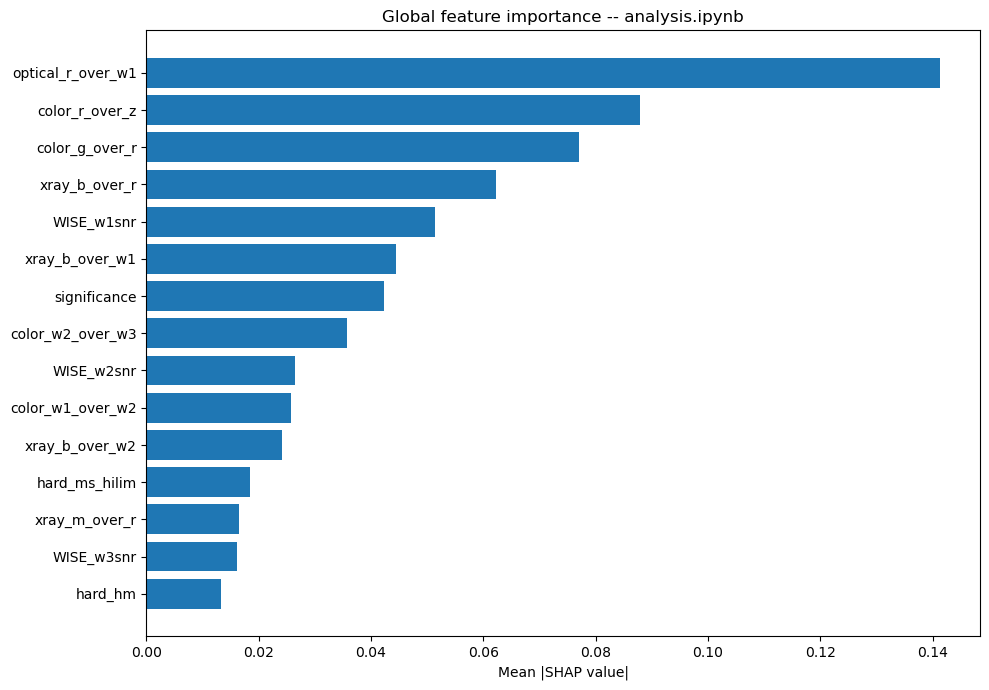

In [7]:
plot_shap_global(
    global_shap, top_n=15,
    save_path=RESULTS_DIR / "figures" / "shap_global.png",
    title="Global feature importance -- analysis.ipynb",
)


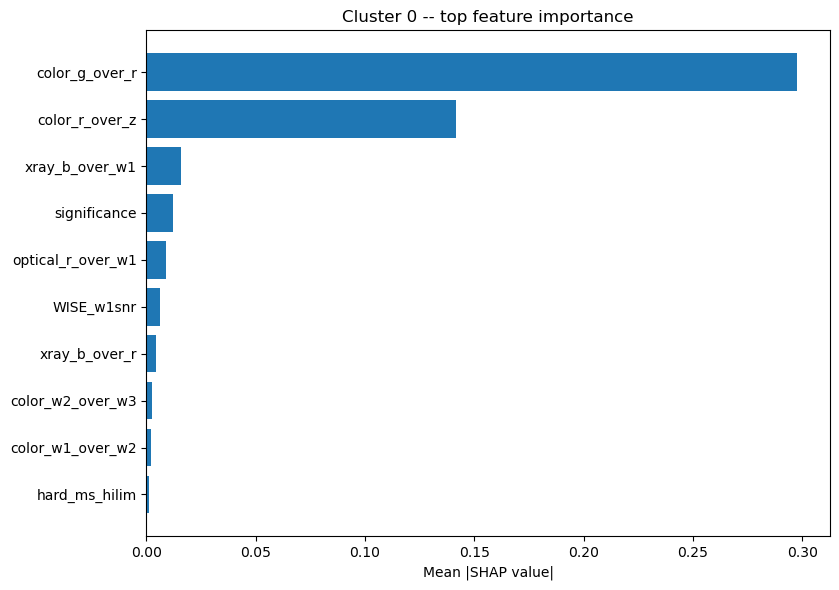

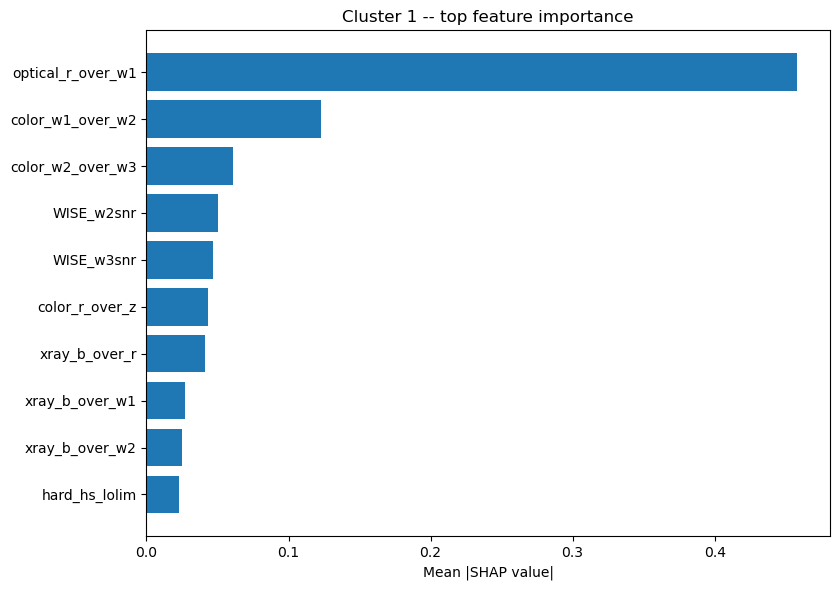

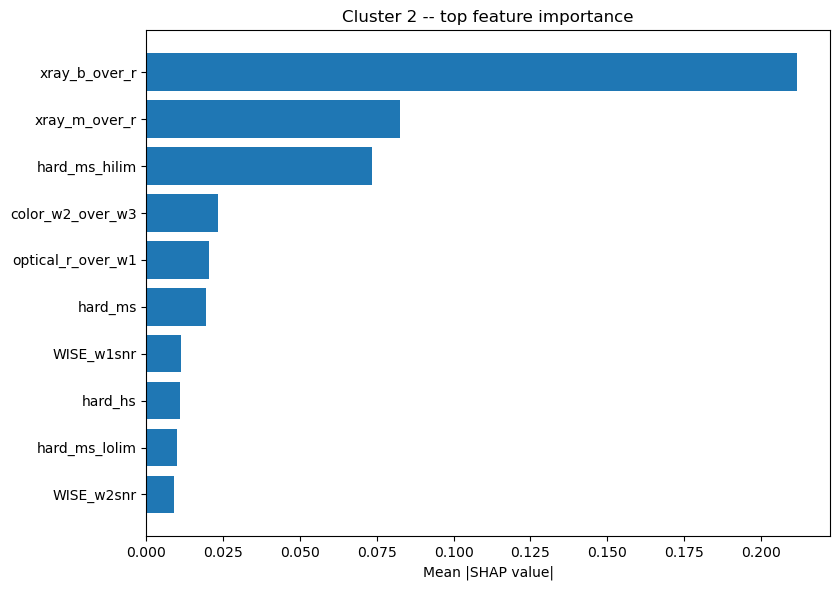

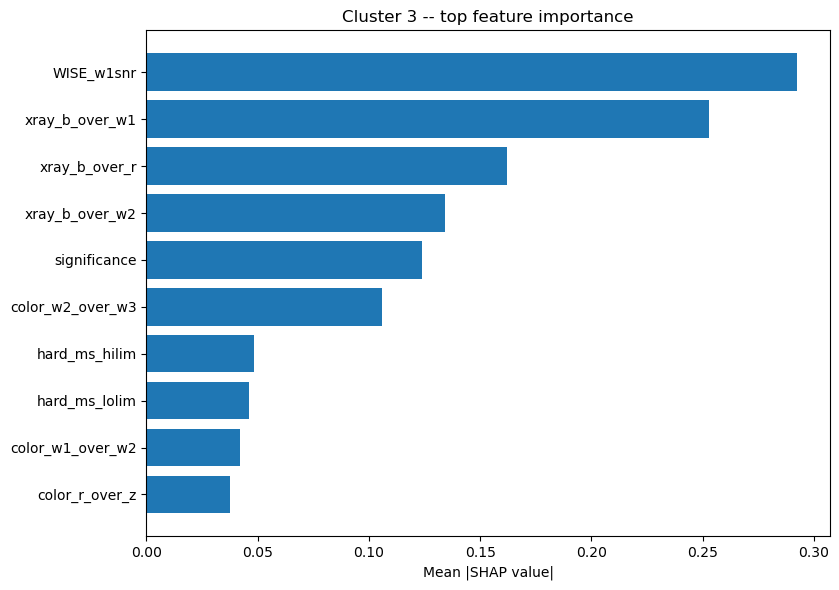

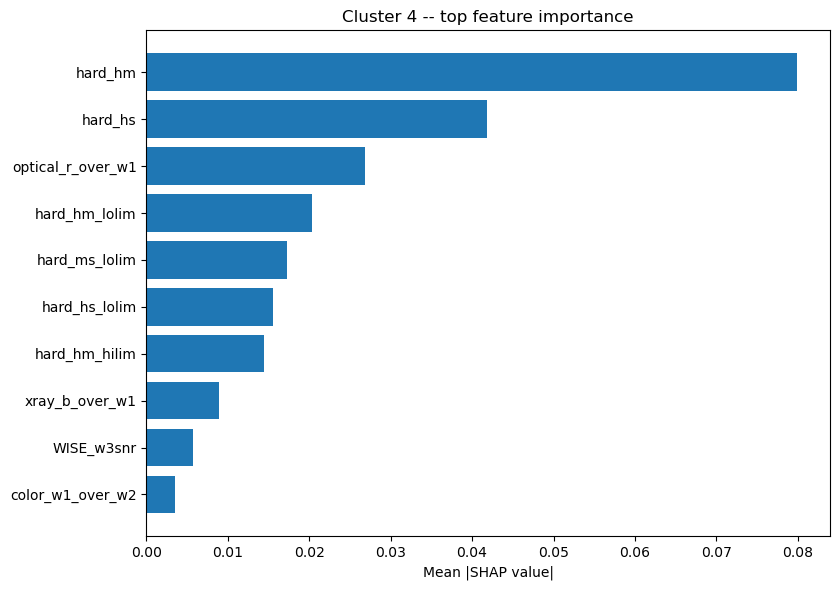

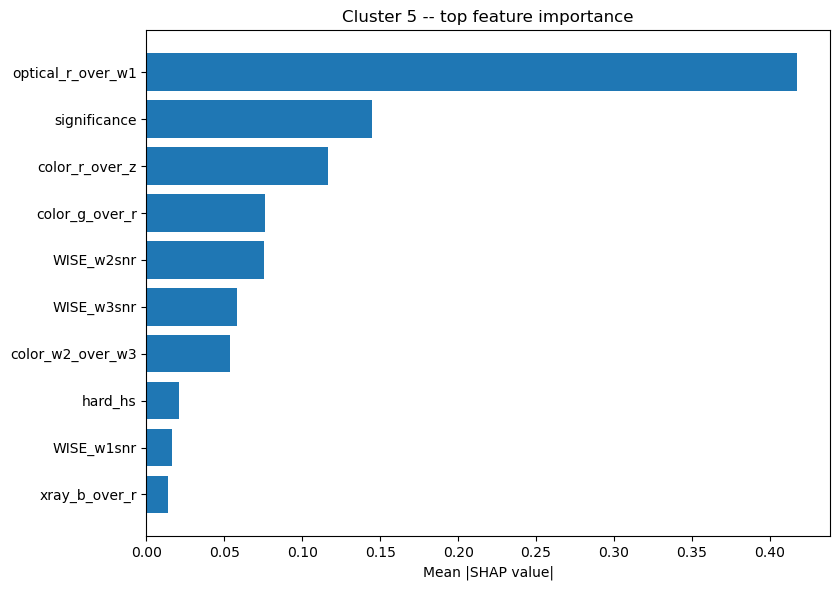

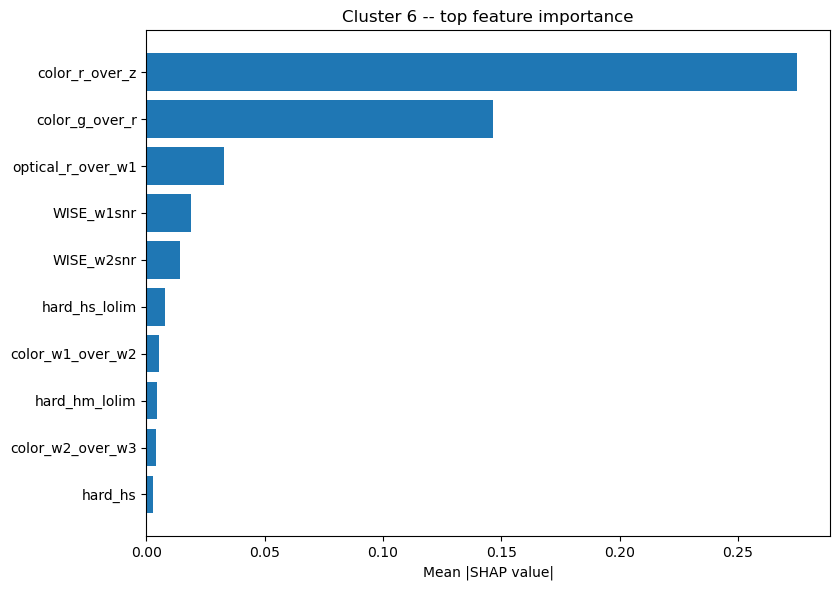

In [8]:
cluster_tables = per_cluster_shap_tables(shap_values, X_shap, model.classes_, top_n=10)
plot_shap_per_cluster(cluster_tables, save_dir=RESULTS_DIR / "figures")


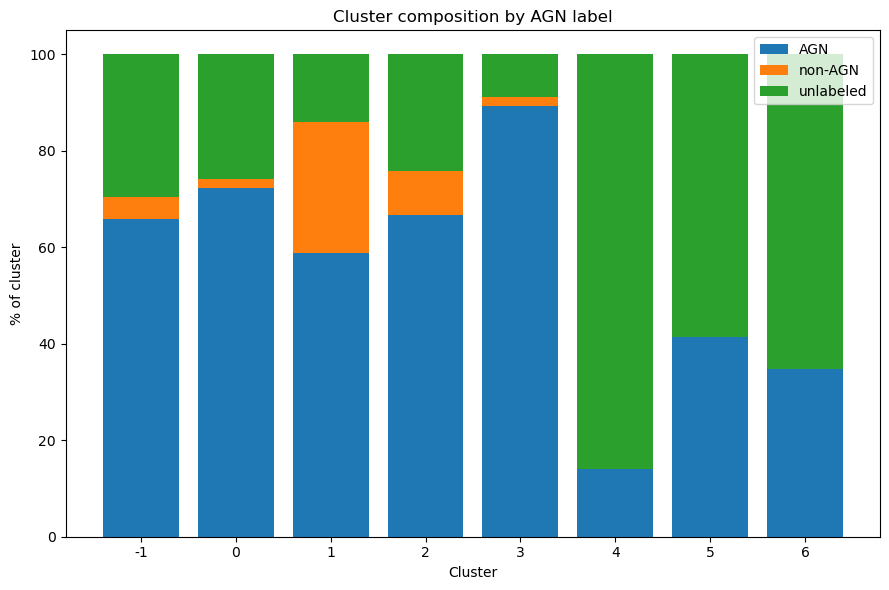

,pct_agn,pct_nonagn,pct_unlabeled
cluster,,,
-1,65.940746,4.455560,29.603694
0,72.222222,1.851852,25.925926
1,58.823529,27.205882,13.970588
2,66.666667,9.259259,24.074074
3,89.360143,1.799088,8.840768
4,13.953488,0.000000,86.046512
5,41.489362,0.000000,58.510638
6,34.693878,0.000000,65.306122


In [9]:
composition = plot_cluster_composition(
    df_sample, cluster_col="cluster", label_col="label_3class",
    save_path=RESULTS_DIR / "figures" / "cluster_composition.png",
)
display(composition)


In [10]:
result = cluster_results[best_key]
print("=== Summary ===")
print(f"Rows: {X.shape[0]}, Columns: {X.shape[1]}")
print(f"Selected HDBSCAN config: {best_key}")
print(f"Clusters: {result.n_clusters}, Noise fraction: {result.noise_fraction:.4f}")
print(f"Silhouette: {result.silhouette:.4f}")
print("Top 5 global SHAP features:", global_shap.head(5)["feature"].tolist())


=== Summary ===
Rows: 25801, Columns: 22
Selected HDBSCAN config: mcs_20_ms_5_leaf
Clusters: 7, Noise fraction: 0.5037
Silhouette: 0.4326
Top 5 global SHAP features: ['optical_r_over_w1', 'color_r_over_z', 'color_g_over_r', 'xray_b_over_r', 'WISE_w1snr']


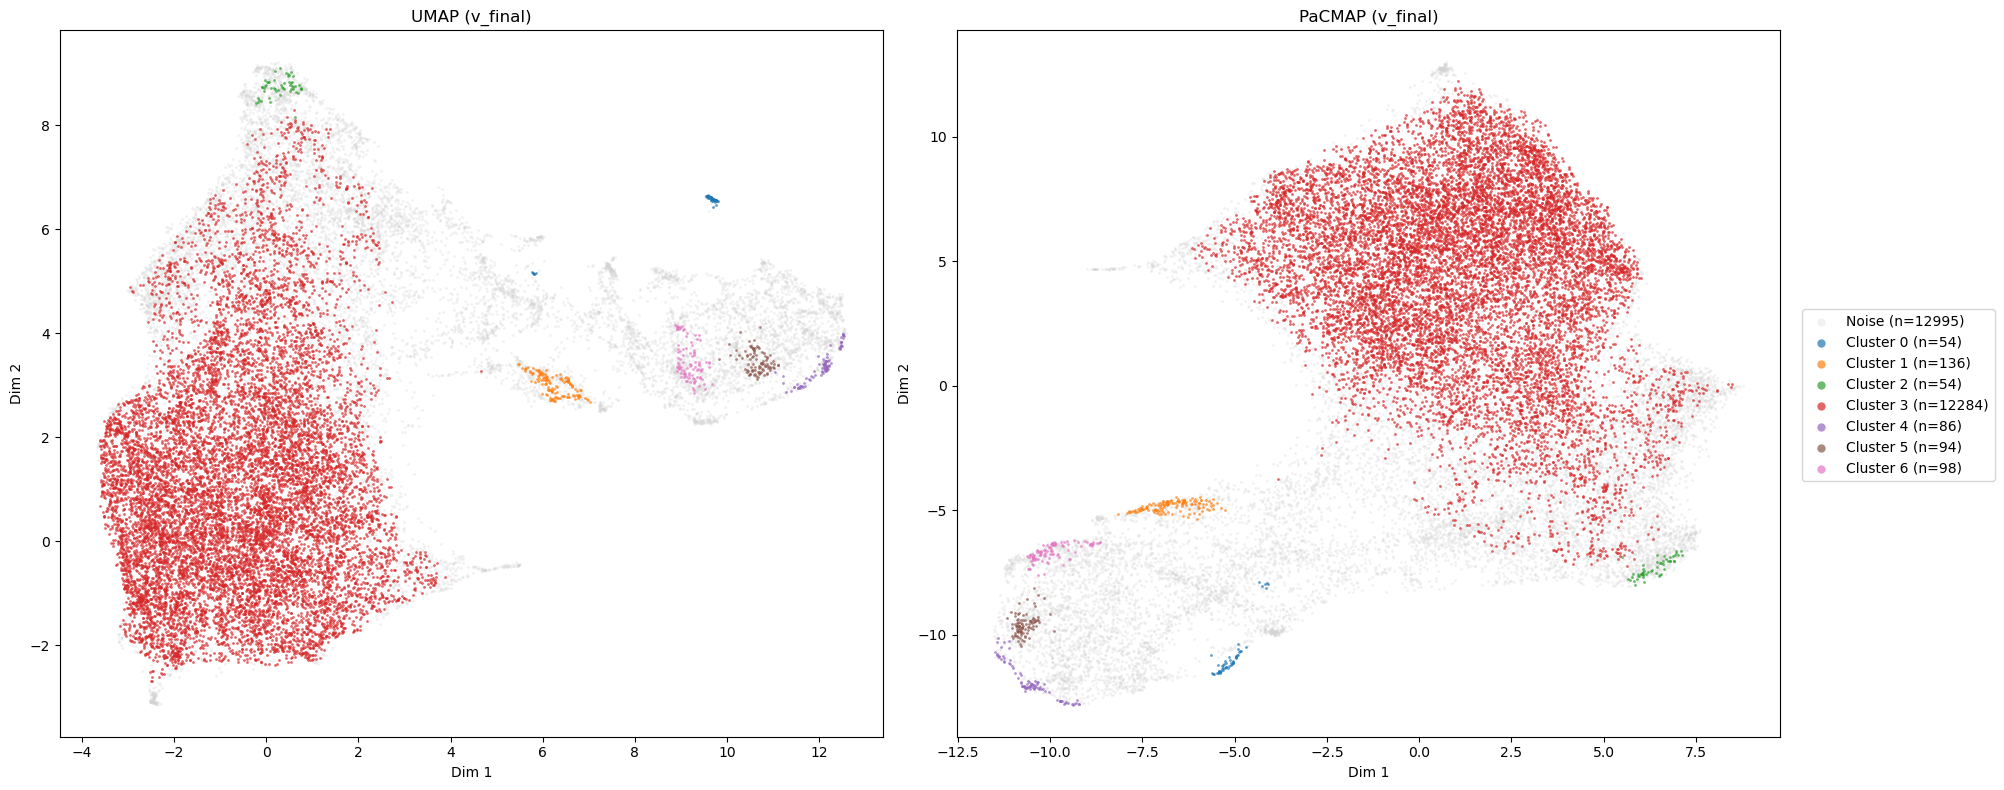

In [11]:
from src.clustering import fit_pacmap
from src.interpretation import plot_embedding_comparison

# Exploratory visualization only: reuses X_scaled and cluster_labels (best
# HDBSCAN config, mcs_20_ms_5_leaf) exactly as produced above -- no feature
# rebuild, no re-tuning. UMAP embedding also reused from the `embedding`
# variable computed earlier in this notebook.
pacmap_embedding = fit_pacmap(X_scaled, n_neighbors=15, n_components=2, random_state=42)

plot_embedding_comparison(
    embedding, pacmap_embedding, cluster_labels,
    title_left="UMAP (v_final)", title_right="PaCMAP (v_final)",
    save_path=RESULTS_DIR / "figures" / "umap_vs_pacmap_final.png",
)


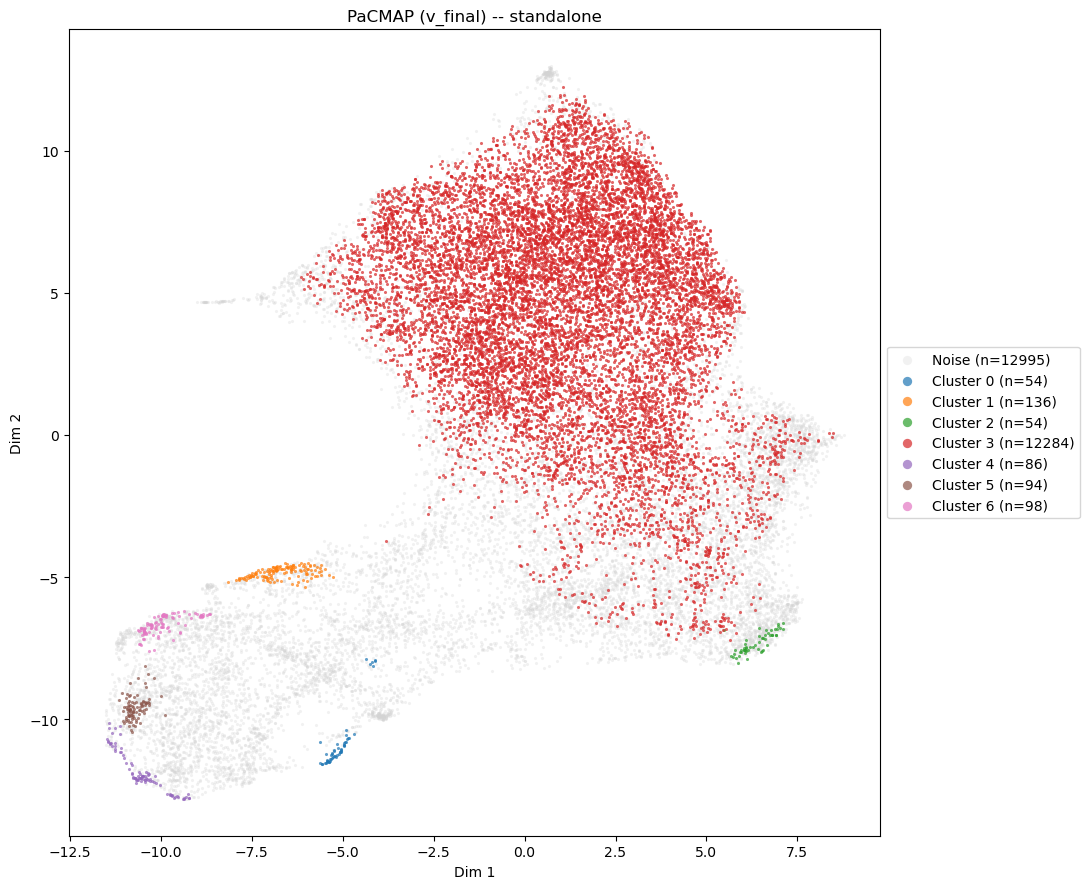

In [12]:
from src.interpretation import plot_embedding_single

plot_embedding_single(
    pacmap_embedding, cluster_labels, title="PaCMAP (v_final) -- standalone",
    save_path=RESULTS_DIR / "figures" / "pacmap_only_final.png",
)


label_3class value counts within v_final's sample:
label_3class
-1     5172
 0      843
 1     7514
 2    12272
Name: count, dtype: int64


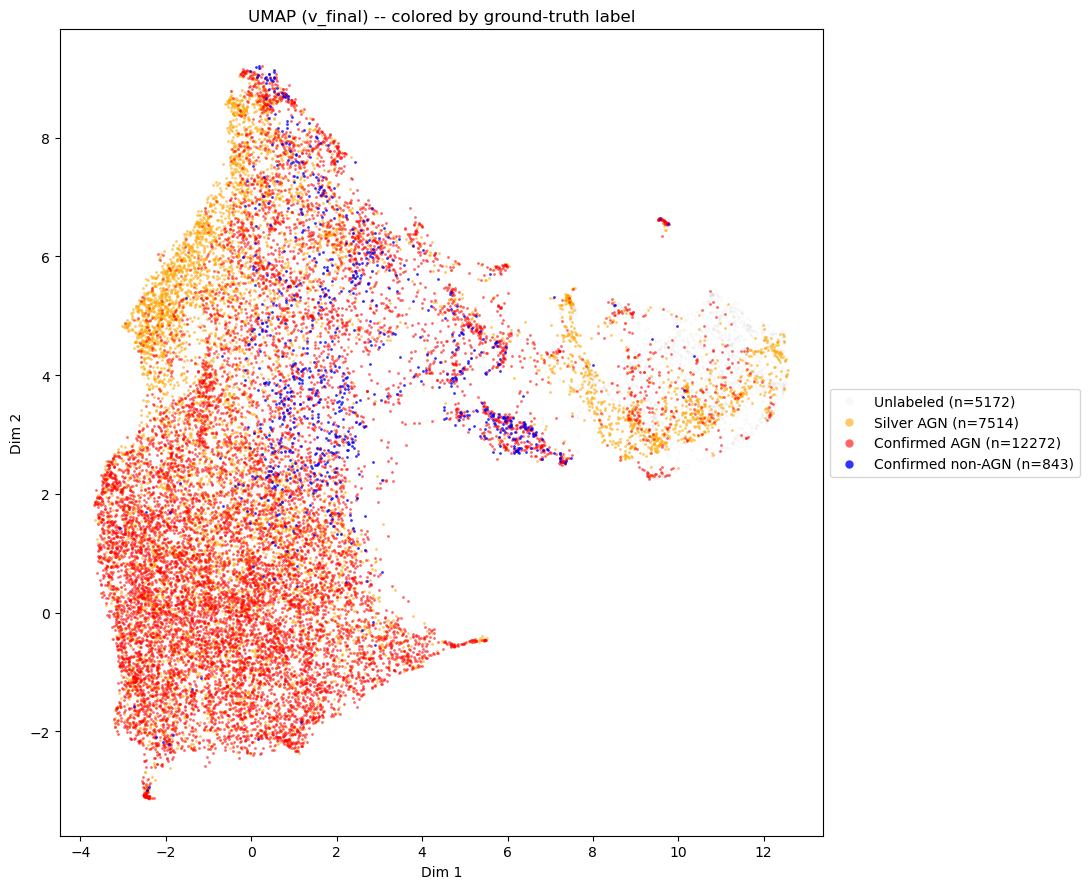

In [13]:
from src.interpretation import plot_embedding_by_label

# Alignment check: cluster_labels, X, df_sample, embedding, and pacmap_embedding
# must all be the same length and in the same row order (v_final never
# reindexes after build_feature_matrix) before overlaying labels/clusters on
# any of them.
assert len(cluster_labels) == len(df_sample) == len(X) == embedding.shape[0] == pacmap_embedding.shape[0]
assert (df_sample["cluster"].to_numpy() == cluster_labels).all()
print("label_3class value counts within v_final's sample:")
print(df_sample["label_3class"].value_counts().sort_index())

plot_embedding_by_label(
    embedding, df_sample["label_3class"].to_numpy(),
    save_path=RESULTS_DIR / "figures" / "umap_by_label_final.png",
)


Top 8 global-SHAP features used for per-cluster distributions: ['optical_r_over_w1', 'color_r_over_z', 'color_g_over_r', 'xray_b_over_r', 'WISE_w1snr', 'xray_b_over_w1', 'significance', 'color_w2_over_w3']


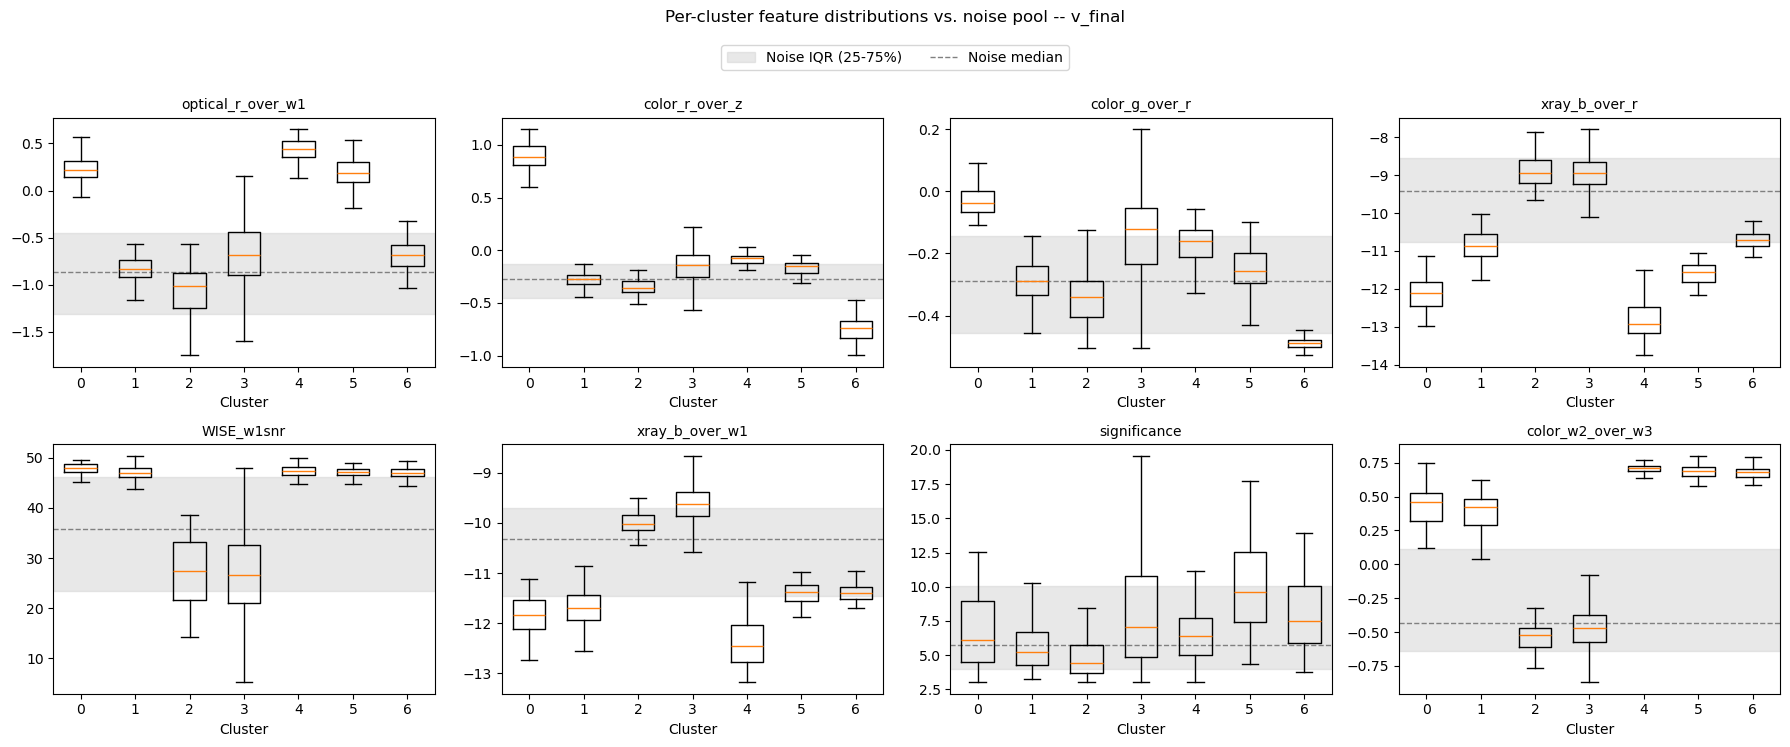

In [14]:
from src.interpretation import plot_feature_distributions_by_cluster

top_features = global_shap.head(8)["feature"].tolist()
print("Top 8 global-SHAP features used for per-cluster distributions:", top_features)

plot_feature_distributions_by_cluster(
    X, cluster_labels, top_features,
    save_path=RESULTS_DIR / "figures" / "feature_distributions_by_cluster_final.png",
)
